# 10 · Binary SLLE: benzene + water with SAFT-γ Mie

**Real-mixture calculation.** Run top to bottom. Model parameters and pure-component data are identified explicitly. These are model predictions, not a fit or an experimental validation of SLLE. See the [course index](../tutorials.md).

<a class="md-button" href="10_binary_slle_saft.ipynb" download>Download notebook</a>


## What this computes
At P=101325 Pa, compute stable liquid/solid flashes, the binary temperature–composition
boundaries, and the **S(benzene)+L₁+L₂ invariant temperature**. At fixed pressure,
the phase rule gives F=C−P+1=0 for a binary with three phases: three-phase
coexistence occurs at one temperature, not across a finite temperature interval.

SAFT uses unchanged bundled Haslam parameters: benzene = 6 aCH, water = H2O.
The solid uses **Tm=278.69 K and ΔHfus=9866.3 J/mol**, the Oliver/Eaton/Huffman
row in the [NIST WebBook](https://webbook.nist.gov/cgi/cbook.cgi?ID=C71432&Mask=4).
We take ΔCp=0. All temperatures exceed water's melting point; only benzene(s)
is supplied. No solid solutions, hydrates or vapour are included.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import SAFTgammaMie
from thermoweave.equilibrium.reduced_held import ReducedChart, ReducedHELD, Solid
from _support import COMPONENTS, DATA, solid_gibbs, held_settings, check_flash, phase_table, phase_label
np.set_printoptions(precision=9, suppress=True)

In [2]:
names = ['benzene', 'water']
model = SAFTgammaMie.from_smiles({n: COMPONENTS[n]['smiles'] for n in names}, pressure_Pa=101325.)
chart = ReducedChart.build([0., 0.], [COMPONENTS[n]['molar_mass_g_mol'] for n in names])
settings = held_settings()  # printed, explicit tolerances; no model modifications
print(settings)

def flash(T, feed, include_solid=True):
    assert T > COMPONENTS['water']['melting_temperature_K']
    solids = [Solid('benzene(s)', [1., 0.], solid_gibbs(T))] if include_solid else []
    return ReducedHELD(model, T, chart, settings, solids=solids).flash(feed)

for T in [275., 279.]:
    out = flash(T, [0.5, 0.5])
    print('T [K]:', T, '; phases:', phase_label(out))
    print(phase_table(out, names))
    print(check_flash(model, T, [0.5, 0.5], out))

SAFT-gamma-Mie automatic assignment: benzene
  SMILES: c1ccccc1
  Formula: C6H6
  Groups: {'aCH': 6}
  Atom-labelled SMILES (labels are 1-based): [cH:1]1[cH:2][cH:3][cH:4][cH:5][cH:6]1
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  aCH x6:
    atoms 1:C(H1)
    atoms 2:C(H1)
    atoms 3:C(H1)
    atoms 4:C(H1)
    atoms 5:C(H1)
    atoms 6:C(H1)
    rule: aromatic CH in a six-membered ring; SMARTS [c;H1;r6]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 6/6 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


SAFT-gamma-Mie automatic assignment: water
  SMILES: O
  Formula: H2O
  Groups: {'H2O': 1}
  Atom-labelled SMILES (labels are 1-based): [OH2:1]
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  H2O x1:
    atoms 1:O(H2)
    rule: whole water molecule; SMARTS [O;H2;X2]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 1/1 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


HELDSettings(stage1_starts=12, screen_points=96, max_iterations=60, max_starts=12, verify_cap=10, verify_random=5, cut_tol=1e-10, polish_tol=2e-09, fd_step=1e-05, polish_max_nfev=60, cluster_radius=0.01, distinct_tol=0.001, max_polish_trials=12, inner_maxiter=300, inner_ftol=1e-13, inner_gtol=1e-10, inner_batch_iters=40, inner_refine=0, polish_pilot_nfev=10, polish_pilot_ratio=0.01, min_neutral_fraction=0.0, stage3_gap=0.001, inner_method='newton', polish_fused=True, seed=0)


T [K]: 275.0 ; phases: S+L
[{'phase': 'liquid', 'mole_fraction_of_total': 0.5001119303030563, 'mass_fraction_of_total': 0.1875929878957369, 'x_benzene': 0.00022381050375732507, 'x_water': 0.9997761894962426}, {'phase': 'benzene(s)', 'mole_fraction_of_total': 0.49988806969694377, 'mass_fraction_of_total': 0.8124070121042631, 'x_benzene': 1.0, 'x_water': 0.0}]
{'species_balance_error_mol': 1.1102230246251565e-16, 'liquid_mu_error_over_RT': 0.0, 'solid_saturation_error_over_RT': np.float64(1.4747578158669228e-12), 'gibbs_reconstruction_error_over_RT': np.float64(1.7617851622020453e-14), 'phase_mole_fractions': [0.5001119303030563, 0.49988806969694377], 'phase_mass_fractions': [0.1875929878957369, 0.8124070121042631]}


T [K]: 279.0 ; phases: L1+L2
[{'phase': 'liquid', 'mole_fraction_of_total': 0.5006467906276683, 'mass_fraction_of_total': 0.8126751626421299, 'x_benzene': 0.9984585836633905, 'x_water': 0.0015414163366095411}, {'phase': 'liquid', 'mole_fraction_of_total': 0.4993532093723318, 'mass_fraction_of_total': 0.18732483735787, 'x_benzene': 0.00025015262116337157, 'x_water': 0.9997498473788365}]
{'species_balance_error_mol': 1.312283615106935e-13, 'liquid_mu_error_over_RT': 5.161012676252463e-13, 'solid_saturation_error_over_RT': 0.0, 'gibbs_reconstruction_error_over_RT': np.float64(0.0), 'phase_mole_fractions': [0.5006467906277341, 0.4993532093723974], 'phase_mass_fractions': [0.8126751626421299, 0.18732483735787]}


## Locate the binary three-phase invariant
First solve liquid-only coexistence, allowing metastable liquids below the
freezing transition. Then find the temperature at which their common benzene
chemical potential equals the pure-solid value:
$\ln(x_B^{L}\gamma_B^{L})=g_B^S/(RT)$.
This is a phase-boundary calculation; it does not fit or adjust any parameter.

In [3]:
from functools import lru_cache
from scipy.optimize import brentq

@lru_cache(maxsize=64)
def liquid_tie_line(T):
    out = flash(float(T), [0.5, 0.5], include_solid=False)
    assert out.certified and out.converged and out.phase_kinds == ['liquid', 'liquid']
    X = np.asarray(sorted(out.mole_fractions, key=lambda x: x[0]))
    assert X[1, 0]-X[0, 0] > 0.5  # reject a trivial same-liquid solution
    return X

def freezing_residual(T):
    organic = liquid_tie_line(float(T))[1]
    mu_B = np.log(organic[0])+model.ln_activity_coefficients(float(T), organic)[0]
    return float(mu_B-solid_gibbs(T))

Tm = COMPONENTS['benzene']['melting_temperature_K']
T_star = brentq(freezing_residual, 278., Tm, xtol=1e-7)
liquids = liquid_tie_line(float(T_star))
print('Predicted binary S+L1+L2 temperature [K]:', T_star)
print('Coexisting liquid compositions [benzene, water]:', liquids)
print('Solid composition:', [1., 0.])
assert abs(freezing_residual(T_star)) < 1e-8

Predicted binary S+L1+L2 temperature [K]: 278.59473755599714
Coexisting liquid compositions [benzene, water]: [[0.000248759 0.999751241]
 [0.998481837 0.001518163]]
Solid composition: [1.0, 0.0]


## Verify actual three-phase equilibrium
Liquid chemical potentials must match; benzene must also match its solid.
Check the candidate tangent plane against a dense composition survey and an
independent HELD flash. In this binary invariant, **phase amounts are not
unique**: three amounts satisfy only two component balances. A flash may return
two phases with the same minimum G. That is compatible with three-phase
coexistence and must not be presented as a finite three-phase region.

In [4]:
mu = np.log(liquids)+model.ln_activity_coefficients_batch(float(T_star), liquids)
np.testing.assert_allclose(mu[0], mu[1], atol=1e-7)
np.testing.assert_allclose(mu[:, 0], solid_gibbs(T_star), atol=1e-7)
three_phases = np.vstack([liquids, [1., 0.]])
beta = np.array([0.35, 0.35, 0.30])  # one valid set of non-unique molar amounts
feed = beta @ three_phases
candidate_g = sum(beta[i]*model.reduced_mixing_gibbs(T_star, x) for i,x in enumerate(liquids)) + beta[2]*solid_gibbs(T_star)
verified = flash(float(T_star), feed)
print('Flash representation at the invariant:', verified.phase_kinds)
print('Three-phase candidate G/RT:', candidate_g, '; flash G/RT:', verified.gibbs)
np.testing.assert_allclose(candidate_g, verified.gibbs, atol=2e-7)
assert verified.certified and verified.converged
xs = np.unique(np.r_[np.linspace(0,1,301), liquids[:,0]])
X = np.column_stack([xs, 1-xs])
lng = model.ln_activity_coefficients_batch(float(T_star), X)
g = np.sum(X*(np.log(np.maximum(X,1e-300))+lng), axis=1)
plane_gap = g-X @ mu[0]
print('Minimum sampled liquid tangent-plane gap:', plane_gap.min())
assert plane_gap.min() > -2e-7

Flash representation at the invariant: ['liquid', 'benzene(s)']
Three-phase candidate G/RT: -0.00103246091980323 ; flash G/RT: -0.0010324609205072809
Minimum sampled liquid tangent-plane gap: -1.5749413492111008e-12


## Draw stable binary boundaries
Below T*, the stable liquidus is the water-rich saturation branch and the other
phase is solid benzene. Above T*, the liquid miscibility gap is stable. Between
T* and the pure benzene melting point there is also a narrow benzene-rich
liquid+solid interval. Resolve it in the second panel rather than omitting it.
The lines below are computed compositions, not boundaries guessed from feed labels.

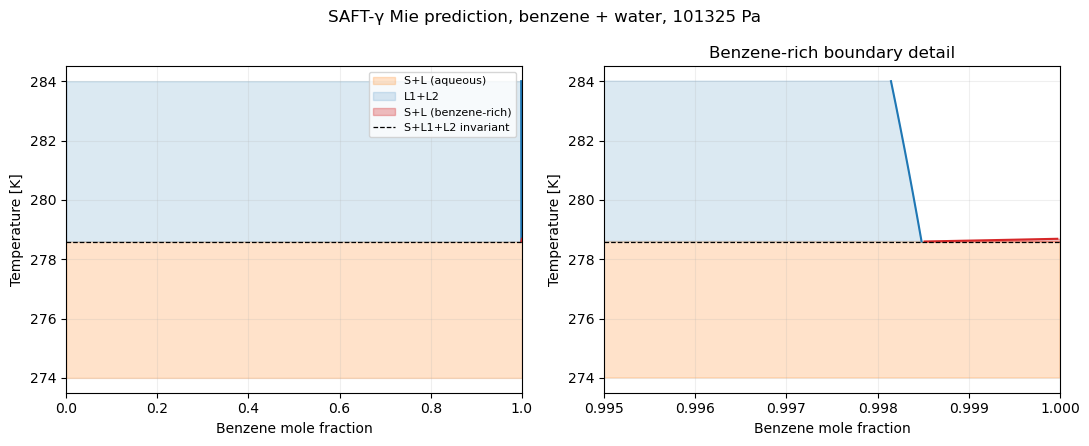

In [5]:
from thermoweave import FusionProperties
from thermoweave.equilibrium.sle import solubility
fusion = FusionProperties(Tm, COMPONENTS['benzene']['enthalpy_of_fusion_J_mol'])
low_T = np.linspace(274., T_star-0.002, 8)
low_x = np.array([solubility(model, 0, float(t), fusion).solubility for t in low_T])
high_T = np.r_[np.linspace(T_star+0.002, Tm-0.002, 4), np.linspace(Tm+0.002, 284., 8)]
ends = np.array([liquid_tie_line(float(t))[:,0] for t in high_T])
mid_T = high_T[high_T < Tm]
right_sle = []
for t in mid_T:
    organic = liquid_tie_line(float(t))[1,0]
    def residual(xb):
        return np.log(xb)+model.ln_activity_coefficients(float(t), [xb,1-xb])[0]-solid_gibbs(t)
    right_sle.append(brentq(residual, organic, 1., xtol=1e-12))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax in axes:
    ax.fill_betweenx(low_T, low_x, 1., color='tab:orange', alpha=.22, label='S+L (aqueous)')
    ax.fill_betweenx(high_T, ends[:,0], ends[:,1], color='tab:blue', alpha=.16, label='L1+L2')
    ax.fill_betweenx(mid_T, right_sle, 1., color='tab:red', alpha=.3, label='S+L (benzene-rich)')
    ax.plot(low_x, low_T, color='tab:orange')
    ax.plot(ends[:,0], high_T, color='tab:blue'); ax.plot(ends[:,1], high_T, color='tab:blue')
    ax.plot(right_sle, mid_T, color='tab:red')
    ax.axhline(T_star, color='black', ls='--', lw=.9, label='S+L1+L2 invariant')
    ax.set(xlabel='Benzene mole fraction', ylabel='Temperature [K]'); ax.grid(alpha=.2)
axes[0].set_xlim(0,1); axes[1].set_xlim(.995,1)
axes[0].legend(fontsize=8); axes[1].set_title('Benzene-rich boundary detail')
fig.suptitle('SAFT-γ Mie prediction, benzene + water, 101325 Pa'); fig.tight_layout(); plt.show()

**Try:** change the feed in `flash`, or replace `model` with a correctly
configured `CosmoRSModel`. Keep fusion data and the pure-liquid reference
consistent. Below water's melting point, add an independently parameterized
ice solid before interpreting the result. Continue with the finite ternary
three-phase region in notebook 11 and the real COSMO-RS calculations in 13.